# Flash drought decomposition reanalysis results

In [1]:
import glob as glob
import xarray as xr
import pandas as pd
import geopandas as gpd
import sys
import os
import numpy as np
import time
import zarr
import matplotlib.pyplot as plt
import gc

In [2]:
sys.path.append('/g/data/mn51/users/jb6465/code/flash-drought/attribution-python')
from attribution import *
from plotting import *
from extract import *

In [3]:
import warnings
import logging
warnings.filterwarnings('ignore') 
logging.getLogger("distributed.worker.memory").setLevel(logging.ERROR)
logging.getLogger("distributed.shuffle._scheduler_plugin").setLevel(logging.ERROR)
logging.getLogger('flox').setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [4]:
import dask
import tempfile
from dask.diagnostics import ProgressBar
from dask.distributed import Client, LocalCluster

dask.config.set({
    # 'array.chunk-size': "256 MiB",
    # 'array.slicing.split_large_chunks': True, #This can make AXIOM very slow
    'distributed.comm.timeouts.connect': '120s',
    'distributed.comm.timeouts.tcp': '120s',
    'distributed.comm.retry.count': 10,
    'distributed.scheduler.allowed-failures': 20,
    "distributed.scheduler.worker-saturation": 1.1, #This should use the new behaviour which helps with memory pile up
})

client = Client(n_workers=10, threads_per_worker=1, local_directory = tempfile.mkdtemp(), memory_limit = "765000mb")
client

2026-05-26 14:52:08,994 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:08,997 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:09,000 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:09,003 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:09,005 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:09,008 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251.19 GiB
2026-05-26 14:52:09,010 - distributed.nanny.memory - WARNING - Ignoring provided memory limit 765000mb due to system memory limit of 251

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: /proxy/46711/status,
Dashboard: /proxy/46711/status,Workers: 10
Total threads: 10,Total memory: 2.45 TiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:44229,Workers: 0
Dashboard: /proxy/46711/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:35861,Total threads: 1
Dashboard: /proxy/44425/status,Memory: 251.19 GiB
Nanny: tcp://127.0.0.1:42873,


In [5]:
short_tall_switch = 'tall'

## Black summer case study

In [5]:
# load in sensitivities
sens_T = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_T.zarr').sens_T
sens_R = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_R.zarr').sens_R
sens_q = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_q.zarr').sens_q
sens_U = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_U.zarr').sens_U

In [6]:
#load in relevant years
RefET_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_ETr.zarr').anom_ET0.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=slice('2016', '2020')).compute()
T_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_T.zarr').anom_T.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=slice('2016', '2020')).compute()
R_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_R.zarr').anom_R.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=slice('2016', '2020')).compute()
q_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_q.zarr').anom_q.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=slice('2016', '2020')).compute()
U_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_U.zarr').anom_U.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=slice('2016', '2020')).compute()

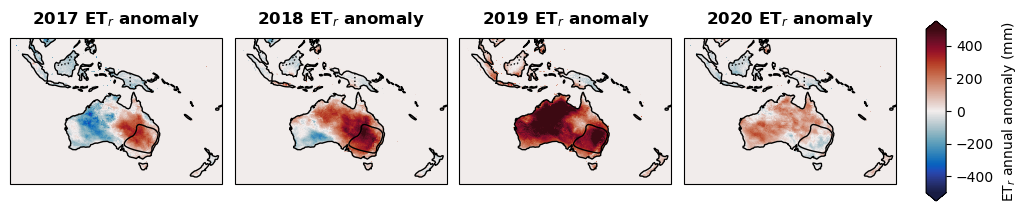

In [7]:
import cmocean
create_multiplot(nrows=1, ncols=4, plot_fontsize=10, title_size=12, figsize=(10, 12), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[RefET_anom.sel(time='2017').sum(dim='time'),RefET_anom.sel(time='2018').sum(dim='time'), RefET_anom.sel(time='2019').sum(dim='time'), RefET_anom.sel(time='2020').sum(dim='time')]],
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        col_titles=['2017 ET$_r$ anomaly', '2018 ET$_r$ anomaly', '2019 ET$_r$ anomaly', '2020 ET$_r$ anomaly'],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.balance],
        cbar_labels=['ET$_r$ annual anomaly (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.02,
        cbar_height = 0.15,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.85/2),
        cbar_mins=[-500],
        cbar_maxs=[500])

In [8]:
import cmocean

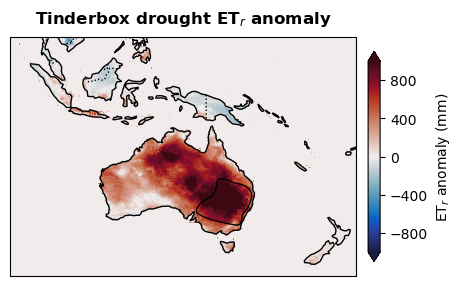

In [9]:
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[RefET_anom.sel(time=slice('2017', '2019')).sum(dim='time')]],
        col_titles=['Tinderbox drought ET$_r$ anomaly'],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.balance],
        cbar_labels=['ET$_r$ anomaly (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-1000],
        cbar_maxs=[1000])

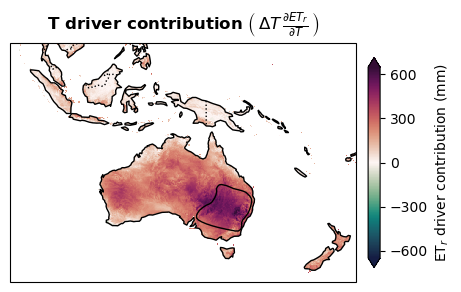

In [13]:
T_cont = mask_ocean((T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).sel(time=slice('2017','2019')).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[T_cont]],
        col_titles=['T driver contribution ' + r"$\left(\,\Delta T\,\frac{\partial ET_r}{\partial T}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-650],
        cbar_maxs=[650])

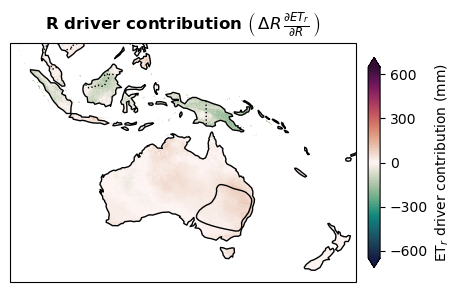

In [14]:
R_cont = mask_ocean((R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).sel(time=slice('2017','2019')).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[R_cont]],
        col_titles=['R driver contribution ' + r"$\left(\,\Delta R\,\frac{\partial ET_r}{\partial R}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-650],
        cbar_maxs=[650])

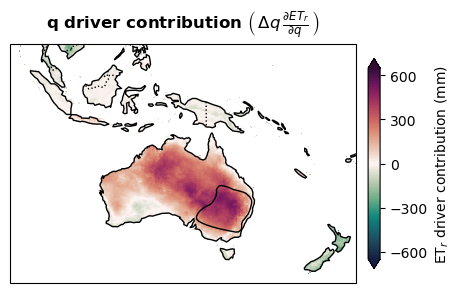

In [15]:
q_cont = mask_ocean((q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).sel(time=slice('2017','2019')).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[q_cont]],
        col_titles=['q driver contribution ' + r"$\left(\,\Delta q\,\frac{\partial ET_r}{\partial q}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-650],
        cbar_maxs=[650])

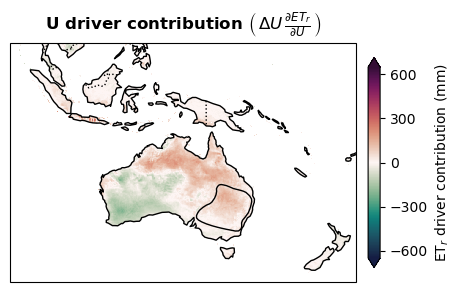

In [16]:
U_cont = mask_ocean((U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).sel(time=slice('2017','2019')).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[U_cont]],
        col_titles=['U driver contribution ' + r"$\left(\,\Delta U\,\frac{\partial ET_r}{\partial U}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-650],
        cbar_maxs=[650])

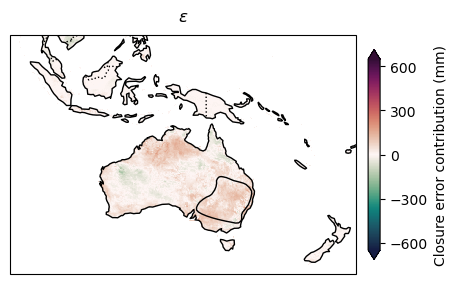

In [17]:
closure = RefET_anom.sel(time=slice('2017', '2019')).sum(dim='time') - (T_cont + R_cont + q_cont + U_cont)
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[closure]],
        col_titles=[r"$\varepsilon$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['Closure error contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-650],
        cbar_maxs=[650])

In [18]:
from scipy.stats import rankdata

drivers = [T_cont, R_cont, q_cont, U_cont]
names = ['T', 'R', 'q', 'U']

stacked = xr.concat(drivers, dim='driver', coords='minimal', compat='override').assign_coords(driver=names)

ranked = xr.DataArray(rankdata(-stacked, axis=0), dims=stacked.dims, coords=stacked.coords)
ranked_drivers = {n: ranked.sel(driver=n) for n in names}


In [19]:
dominant_driver = ranked.idxmin(dim='driver')
driver_map = {'T': 1, 'R': 2, 'q': 3, 'U': 4}

dominant_driver_num = xr.DataArray(np.vectorize(driver_map.get)(dominant_driver.values), dims=dominant_driver.dims, coords=dominant_driver.coords)


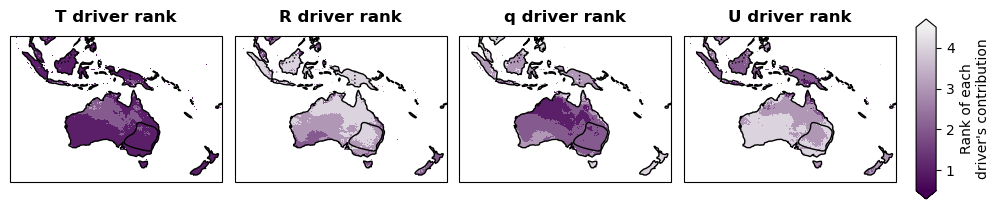

In [20]:
import cmocean
from matplotlib import colors
import matplotlib.colors as mcolors

create_multiplot(nrows=1, ncols=4, plot_fontsize=10, title_size=12, figsize=(10, 12), plot_extent=[90, 180, -40, 9], plot_marker=None,
        plot_list=[[ranked_drivers['T'], ranked_drivers['R'], ranked_drivers['q'], ranked_drivers['U']]],
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        col_titles=['T driver rank', 'R driver rank', 'q driver rank', 'U driver rank'],
        col_titles_all_rows_switch=False,
        cmap_list=[mcolors.LinearSegmentedColormap.from_list('mono', ['#440154', '#f0f0f0'])],
        cbar_labels=["Rank of each\ndriver's contribution"],
        cbar_extensions=['both'],
        cbar_width = 0.02,
        cbar_height = 0.15,
        cbar_nticks = [4],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.92, 0.85/2),
        cbar_mins=[0.5],
        cbar_maxs=[4.5])

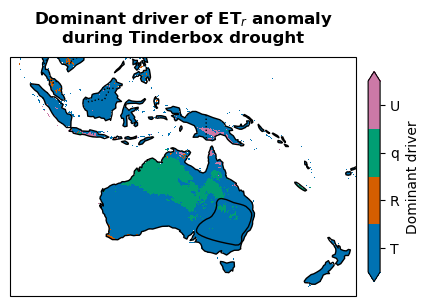

In [21]:
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=[90, 180, -40, 9], plot_marker=None,
        shapefile = '/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp',
        shapefile_linewidth = 1,
        plot_list=[[dominant_driver_num.astype('float')]],
        col_titles=['Dominant driver of ET$_r$ anomaly\nduring Tinderbox drought'],
        col_titles_all_rows_switch=False,
        cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
        cbar_labels=['Dominant driver'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [4],
        cbar_tick_labels = ['-', 'T','R','q','U',],
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[0.5],
        cbar_maxs=[4.5])

In [22]:
import rioxarray
import geopandas as gpd

ET0_anom = ET0_anom.rio.write_crs("EPSG:4326")  
shp = gpd.read_file("/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp").to_crs(ET0_anom.rio.crs)
masked = ET0_anom.rio.clip(shp.geometry, shp.crs)


In [23]:
plt.rcParams.update({'font.size': 16}) 
end_year ='2019'
start_year = '2017'

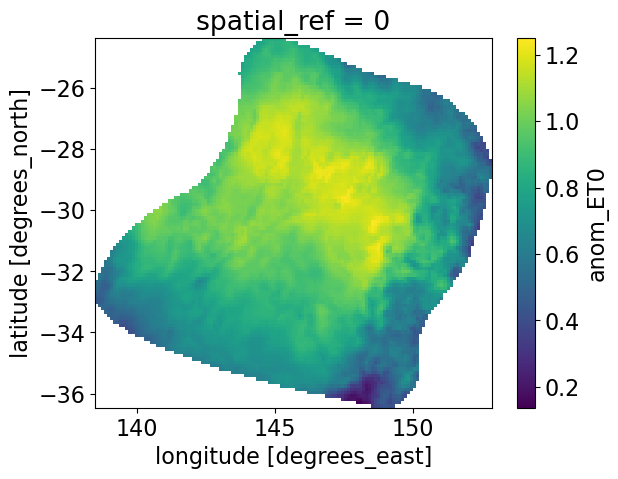

In [24]:
masked.sel(time=slice(start_year, end_year)).mean(dim='time').plot()

In [25]:
T_cont = (T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).sel(time=slice(start_year,end_year))
R_cont = (R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).sel(time=slice(start_year,end_year))
q_cont = (q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).sel(time=slice(start_year,end_year))
U_cont = (U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).sel(time=slice(start_year,end_year))

In [26]:

masked_T_cont = T_cont.rio.write_crs("EPSG:4326").rio.clip(
    gpd.read_file("/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp")
       .to_crs(T_cont.rio.write_crs("EPSG:4326").rio.crs).geometry, T_cont.rio.write_crs("EPSG:4326").rio.crs)

masked_R_cont = R_cont.rio.write_crs("EPSG:4326").rio.clip(
    gpd.read_file("/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp")
       .to_crs(R_cont.rio.write_crs("EPSG:4326").rio.crs).geometry, R_cont.rio.write_crs("EPSG:4326").rio.crs)

masked_q_cont = q_cont.rio.write_crs("EPSG:4326").rio.clip(
    gpd.read_file("/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp")
       .to_crs(q_cont.rio.write_crs("EPSG:4326").rio.crs).geometry, q_cont.rio.write_crs("EPSG:4326").rio.crs)

masked_U_cont = U_cont.rio.write_crs("EPSG:4326").rio.clip(
    gpd.read_file("/g/data/mn51/users/jb6465/data/flash_drought/shapefiles/drought_focus_region/smooth_polygon_drought_focusArea.shp")
       .to_crs(U_cont.rio.write_crs("EPSG:4326").rio.crs).geometry, U_cont.rio.write_crs("EPSG:4326").rio.crs)


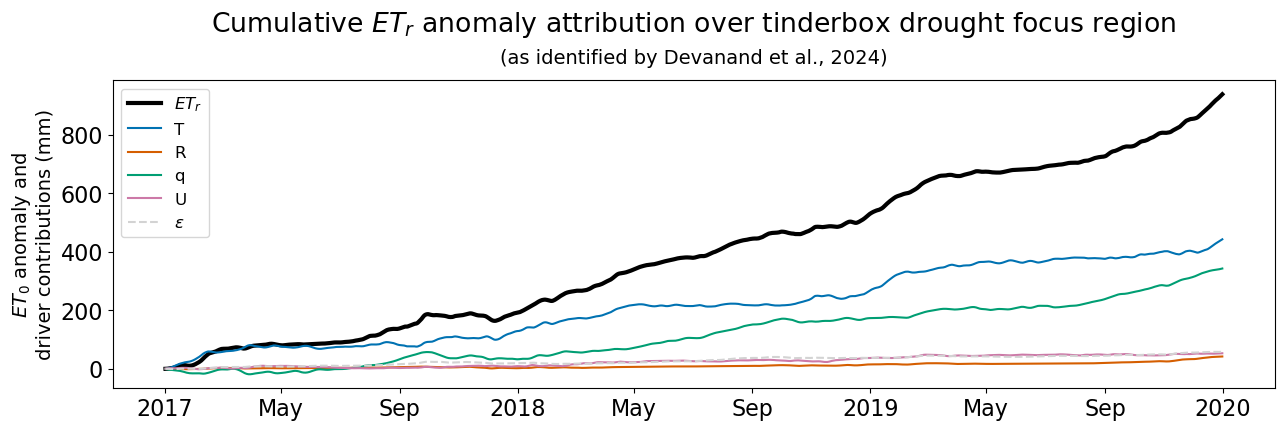

In [27]:
RefET_ts = masked.sel(time=slice(start_year, end_year)).mean(dim=('lat','lon'))
T_ts = masked_T_cont.mean(dim=('lat','lon'))
q_ts = masked_q_cont.mean(dim=('lat','lon'))
R_ts = masked_R_cont.mean(dim=('lat','lon'))
U_ts = masked_U_cont.mean(dim=('lat','lon'))
closure_ts = RefET_ts - T_ts - q_ts - R_ts - U_ts
 
(RefET_ts.cumsum(dim='time')).plot(color='black', label='$ET_{r}$', figsize=(15,4), linewidth=3)
(T_ts.cumsum(dim='time')).plot(color='#0072B2', label='T')
(R_ts.cumsum(dim='time')).plot(color='#D55E00', label='R')
(q_ts.cumsum(dim='time')).plot(color='#009E73', label='q')
(U_ts.cumsum(dim='time')).plot(color='#CC79A7', label='U')

(closure_ts.cumsum(dim='time')).plot(color='lightgrey', linestyle='--', label=r"$\varepsilon$")
plt.title('Cumulative $ET_{r}$ anomaly attribution over tinderbox drought focus region', pad=35)
plt.text(0.5, 1.04, "(as identified by Devanand et al., 2024)", ha='center', va='bottom', transform=plt.gca().transAxes, fontsize=14)
plt.xlabel('')
plt.ylabel('$ET_{0}$ anomaly and\ndriver contributions (mm)', fontsize=14)
plt.legend(fontsize=12)

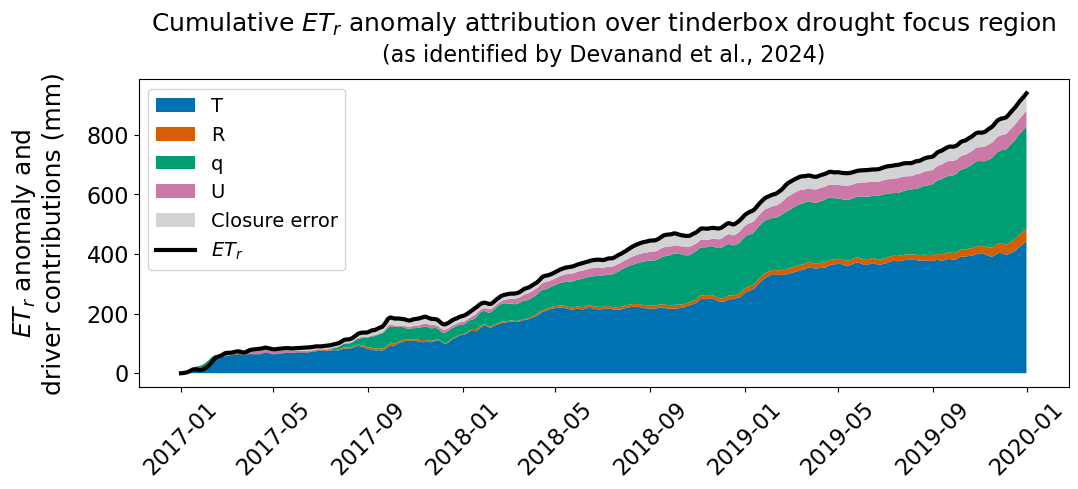

In [31]:
import matplotlib.pyplot as plt
import numpy as np


RefET_cum = RefET_ts.cumsum(dim='time')
T_cum = T_ts.cumsum(dim='time')
q_cum = q_ts.cumsum(dim='time')
R_cum = R_ts.cumsum(dim='time')
U_cum = U_ts.cumsum(dim='time')
closure_cum = closure_ts.cumsum(dim='time')


drivers_cum = np.vstack([
    T_cum.values,
    R_cum.values,
    q_cum.values,
    U_cum.values,
    closure_cum.values  # optional: on top
])


colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', 'lightgrey']


fig, ax = plt.subplots(figsize=(12,4))
ax.stackplot(RefET_ts.time.values, drivers_cum, labels=['T','R','q','U','Closure error'], colors=colors)
ax.plot(RefET_ts.time.values, RefET_cum.values, color='black', linewidth=3, label='$ET_r$')

plt.title('Cumulative $ET_{r}$ anomaly attribution over tinderbox drought focus region', pad=35, size=18)
plt.text(0.5, 1.04, "(as identified by Devanand et al., 2024)", ha='center', va='bottom', transform=plt.gca().transAxes, fontsize=16)
ax.set_ylabel('$ET_{r}$ anomaly and\ndriver contributions (mm)', fontsize=18, labelpad=15)
plt.xticks(rotation=45) 
ax.legend(fontsize=14)
plt.show()


## other case studies 

change case study period, domain and point location accordingly

In [24]:
case_study_period = slice('2019-09-01', '2019-12-31')
case_study_domain = [140, 147, -9.5, -20]
case_study_focus_point = (-16.995, 145.42323)

In [25]:
RefET_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_ETr.zarr').anom_ET0.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=case_study_period).compute()

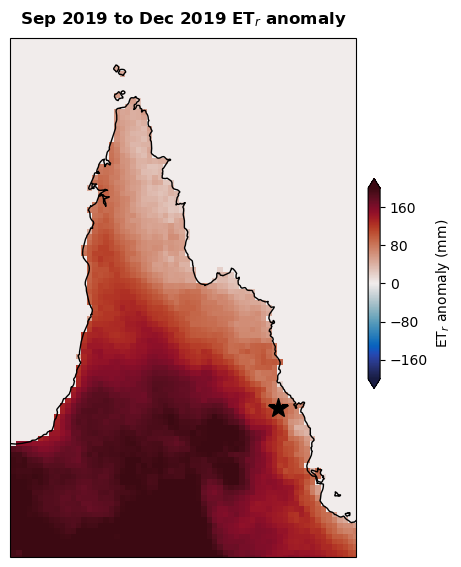

In [26]:
import cmocean
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[RefET_anom.sum(dim='time')]],
        col_titles=[f"{pd.to_datetime(case_study_period.start).strftime('%b %Y')} to {( pd.to_datetime(case_study_period.stop) - pd.Timedelta(days=1)).strftime('%b %Y')} ET$_r$ anomaly"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.balance],
        cbar_labels=['ET$_r$ anomaly (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-200],
        cbar_maxs=[200])

In [27]:
#load in relevant years
T_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_T.zarr').anom_T.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=case_study_period).compute()
R_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_R.zarr').anom_R.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=case_study_period).compute()
q_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_q.zarr').anom_q.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=case_study_period).compute()
U_anom = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/anoms/anom_U.zarr').anom_U.chunk({'time':-1, 'lat':'auto', 'lon':'auto'}).sel(time=case_study_period).compute()

In [28]:
# load in sensitivities
sens_T = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_T.zarr').sens_T
sens_R = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_R.zarr').sens_R
sens_q = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_q.zarr').sens_q
sens_U = xr.open_dataset('/g/data/mn51/users/jb6465/data/flash_drought/reanalysis/BARRA-R2/RefET/ETr/driver_sensitivities/sens_U.zarr').sens_U

In [29]:
import cmocean

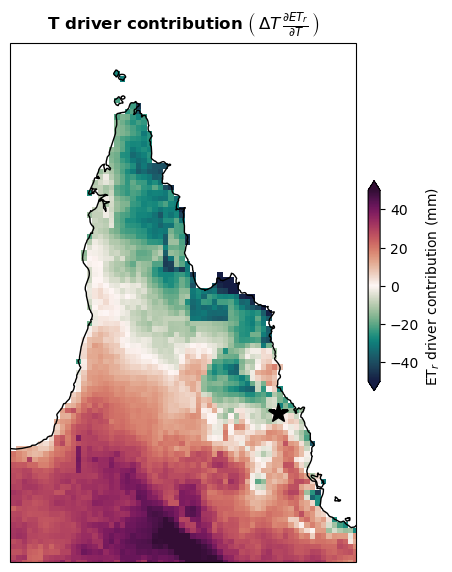

In [30]:
T_cont = mask_ocean((T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).sel(time=case_study_period).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[T_cont]],
        col_titles=['T driver contribution ' + r"$\left(\,\Delta T\,\frac{\partial ET_r}{\partial T}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-50],
        cbar_maxs=[50])

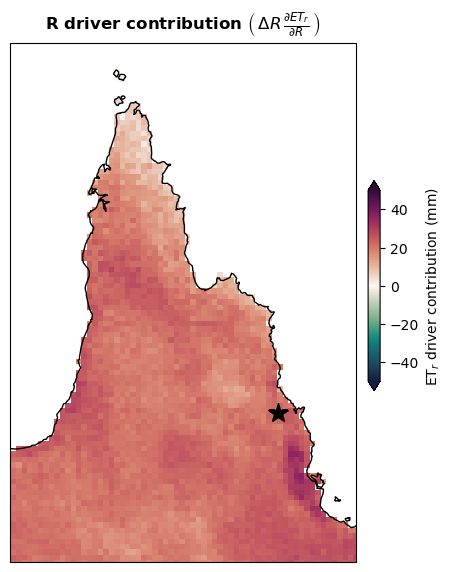

In [31]:
R_cont = mask_ocean((R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).sel(time=case_study_period).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[R_cont]],
        col_titles=['R driver contribution ' + r"$\left(\,\Delta R\,\frac{\partial ET_r}{\partial R}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-50],
        cbar_maxs=[50])

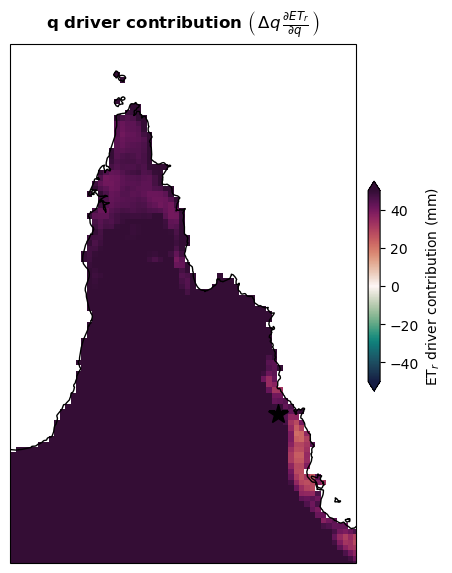

In [32]:
q_cont = mask_ocean((q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).sel(time=case_study_period).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[q_cont]],
        col_titles=['q driver contribution ' + r"$\left(\,\Delta q\,\frac{\partial ET_r}{\partial q}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-50],
        cbar_maxs=[50])

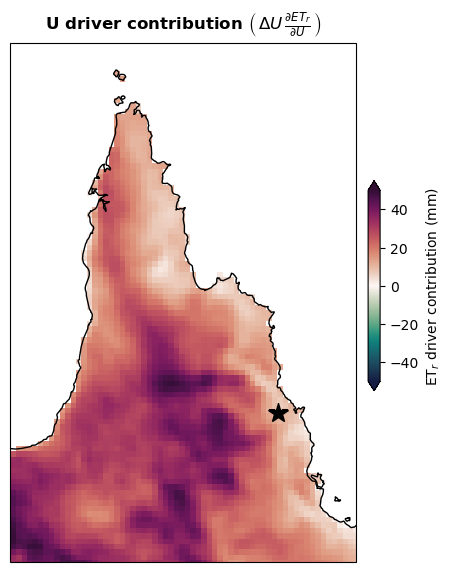

In [33]:
U_cont = mask_ocean((U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).sel(time=case_study_period).sum(dim='time'))

create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[U_cont]],
        col_titles=['U driver contribution ' + r"$\left(\,\Delta U\,\frac{\partial ET_r}{\partial U}\,\right)$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['ET$_r$ driver contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-50],
        cbar_maxs=[50])

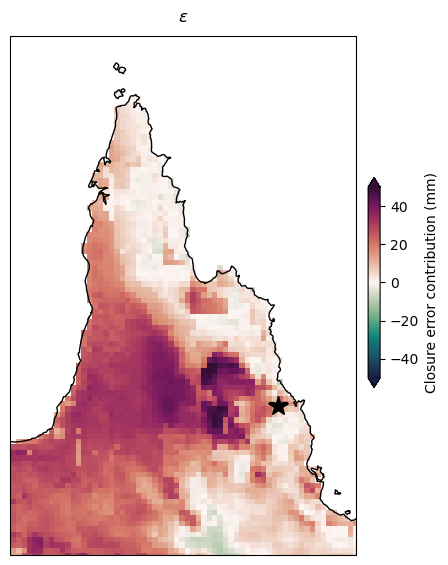

In [34]:
closure = RefET_anom.sel(time=case_study_period).sum(dim='time') - (T_cont + R_cont + q_cont + U_cont)
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = None,
        plot_list=[[closure]],
        col_titles=[r"$\varepsilon$"],
        col_titles_all_rows_switch=False,
        cmap_list=[cmocean.cm.curl],
        cbar_labels=['Closure error contribution (mm)'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [5],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[-50],
        cbar_maxs=[50])

In [35]:
from scipy.stats import rankdata

drivers = [T_cont, R_cont, q_cont, U_cont]
names = ['T', 'R', 'q', 'U']

stacked = xr.concat(drivers, dim='driver', coords='minimal', compat='override').assign_coords(driver=names)

ranked = xr.DataArray(rankdata(-stacked, axis=0), dims=stacked.dims, coords=stacked.coords)
ranked_drivers = {n: ranked.sel(driver=n) for n in names}


In [36]:
dominant_driver = ranked.idxmin(dim='driver')
driver_map = {'T': 1, 'R': 2, 'q': 3, 'U': 4}

dominant_driver_num = xr.DataArray(np.vectorize(driver_map.get)(dominant_driver.values), dims=dominant_driver.dims, coords=dominant_driver.coords)


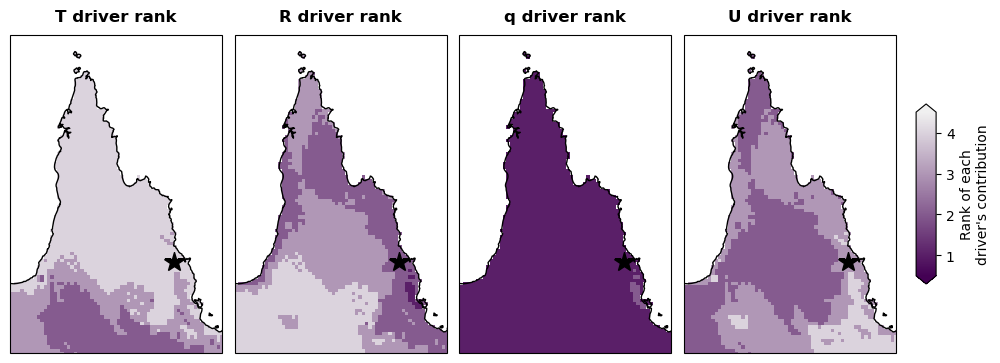

In [37]:
import cmocean
from matplotlib import colors
import matplotlib.colors as mcolors

create_multiplot(nrows=1, ncols=4, plot_fontsize=10, title_size=12, figsize=(10, 12), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        plot_list=[[ranked_drivers['T'], ranked_drivers['R'], ranked_drivers['q'], ranked_drivers['U']]],
        shapefile = None,
        shapefile_linewidth = 1,
        col_titles=['T driver rank', 'R driver rank', 'q driver rank', 'U driver rank'],
        col_titles_all_rows_switch=False,
        cmap_list=[mcolors.LinearSegmentedColormap.from_list('mono', ['#440154', '#f0f0f0'])],
        cbar_labels=["Rank of each\ndriver's contribution"],
        cbar_extensions=['both'],
        cbar_width = 0.02,
        cbar_height = 0.15,
        cbar_nticks = [4],
        cbar_tick_labels = None,
        cbar_x_y_loc = (0.92, 0.85/2),
        cbar_mins=[0.5],
        cbar_maxs=[4.5])

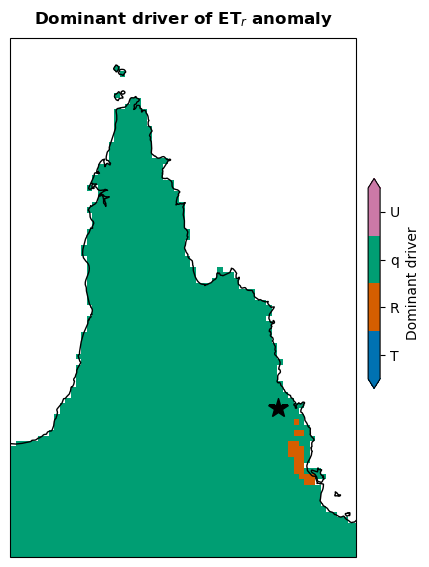

In [38]:
create_multiplot(nrows=1, ncols=1, plot_fontsize=10, title_size=12, figsize=(4, 6), plot_extent=case_study_domain, plot_marker=case_study_focus_point,
        shapefile = None,
        shapefile_linewidth = 1,
        plot_list=[[dominant_driver_num.astype('float')]],
        col_titles=['Dominant driver of ET$_r$ anomaly'],
        col_titles_all_rows_switch=False,
        cmap_list=[colors.ListedColormap(['#0072B2','#D55E00','#009E73','#CC79A7'])],
        cbar_labels=['Dominant driver'],
        cbar_extensions=['both'],
        cbar_width = 0.03,
        cbar_height = 0.35,
        cbar_nticks = [4],
        cbar_tick_labels = ['-', 'T','R','q','U',],
        cbar_x_y_loc = (0.93, 0.65/2),
        cbar_mins=[0.5],
        cbar_maxs=[4.5])

In [39]:
RefET_ts = RefET_anom.sel(lat=case_study_focus_point[0], lon=case_study_focus_point[1], method='nearest').sel(time=case_study_period)

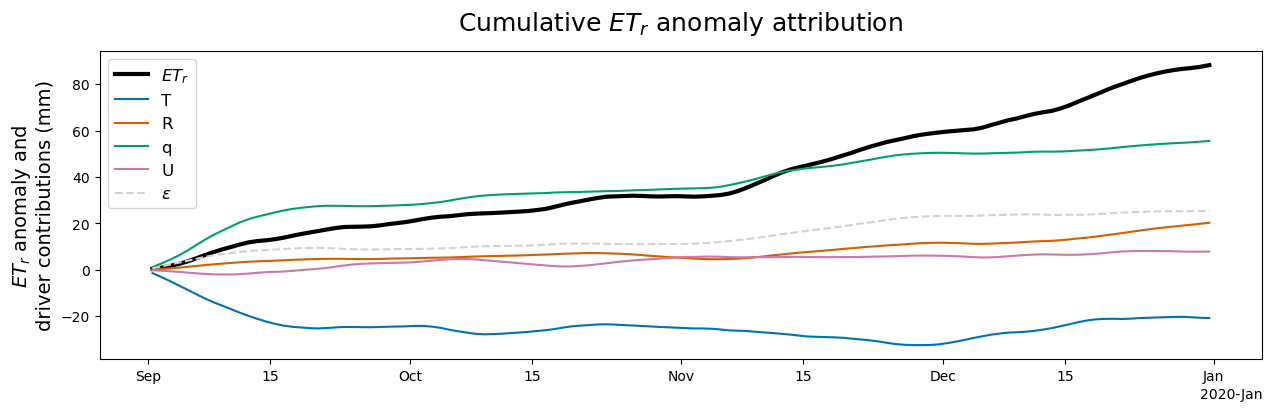

In [40]:
T_ts = (T_anom*sens_T.sel(doy=T_anom['time'].dt.dayofyear)).sel(lat=case_study_focus_point[0], lon=case_study_focus_point[1], method='nearest').sel(time=case_study_period)
q_ts = (q_anom*sens_q.sel(doy=q_anom['time'].dt.dayofyear)).sel(lat=case_study_focus_point[0], lon=case_study_focus_point[1], method='nearest').sel(time=case_study_period)
R_ts = (R_anom*sens_R.sel(doy=R_anom['time'].dt.dayofyear)).sel(lat=case_study_focus_point[0], lon=case_study_focus_point[1], method='nearest').sel(time=case_study_period)
U_ts = (U_anom*sens_U.sel(doy=U_anom['time'].dt.dayofyear)).sel(lat=case_study_focus_point[0], lon=case_study_focus_point[1], method='nearest').sel(time=case_study_period)
closure_ts = RefET_ts - T_ts - q_ts - R_ts - U_ts
 
(RefET_ts.cumsum(dim='time')).plot(color='black', label='$ET_{r}$', figsize=(15,4), linewidth=3)
(T_ts.cumsum(dim='time')).plot(color='#0072B2', label='T')
(R_ts.cumsum(dim='time')).plot(color='#D55E00', label='R')
(q_ts.cumsum(dim='time')).plot(color='#009E73', label='q')
(U_ts.cumsum(dim='time')).plot(color='#CC79A7', label='U')

(closure_ts.cumsum(dim='time')).plot(color='lightgrey', linestyle='--', label=r"$\varepsilon$")
plt.title('Cumulative $ET_{r}$ anomaly attribution', pad=15, size=18)
plt.xlabel('')
plt.ylabel('$ET_{r}$ anomaly and\ndriver contributions (mm)', fontsize=14)
plt.legend(fontsize=12)

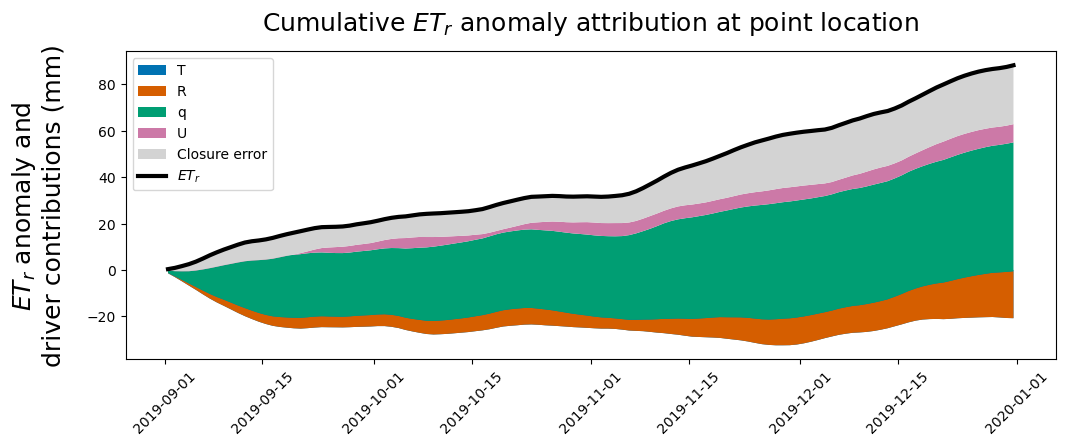

In [41]:
import matplotlib.pyplot as plt
import numpy as np


RefET_cum = RefET_ts.cumsum(dim='time')
T_cum = T_ts.cumsum(dim='time')
q_cum = q_ts.cumsum(dim='time')
R_cum = R_ts.cumsum(dim='time')
U_cum = U_ts.cumsum(dim='time')
closure_cum = closure_ts.cumsum(dim='time')


drivers_cum = np.vstack([
    T_cum.values,
    R_cum.values,
    q_cum.values,
    U_cum.values,
    closure_cum.values  # optional: on top
])


colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', 'lightgrey']


fig, ax = plt.subplots(figsize=(12,4))
ax.stackplot(RefET_ts.time.values, drivers_cum, labels=['T','R','q','U','Closure error'], colors=colors)
ax.plot(RefET_ts.time.values, RefET_cum.values, color='black', linewidth=3, label='$ET_r$')

plt.title('Cumulative $ET_{r}$ anomaly attribution at point location', pad=15, size=18)
ax.set_ylabel('$ET_{r}$ anomaly and\ndriver contributions (mm)', fontsize=18, labelpad=15)
plt.xticks(rotation=45) 
ax.legend(fontsize=10, loc='upper left')
plt.show()
